# 📊 Dataset Information

**Note:** The dataset for this project is **not included in this repository** to keep the repository lightweight.  

You can download the dataset from **Kaggle** using the link below:  

[Download The AI in The Workplace Dataset](https://www.kaggle.com/datasets/vedauv/ai-in-the-workplace-job-risk-and-productivity?select=ai_workplace_job_risk.csv)  

Please make sure to place the downloaded CSV file in the same directory as this notebook before running any code.

# Importing

## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

## Import CSV And convert to DataFrame

In [2]:
df = pd.read_csv('ai_workplace_job_risk.csv')

# Preprocessing

## Frist five row

In [3]:
df.head()

,worker_id,industry,job_role,region,company_size,work_mode,education,experience_years,salary_usd_k,routine_task_pct,creativity_score,interpersonal_score,tech_skill_score,automation_exposure_pct,ai_tools_used,ai_hours_week,ai_training_hours_year,company_ai_policy,productivity_gain_pct,job_at_risk
0,W00001,Manufacturing,Manager,Europe,500-4999,Remote,Bachelor,17,66.1,30.4,75.2,39.4,27.4,42.6,0,0.6,14.7,1,18.9,1
1,W00002,Consulting,Researcher,North America,5000+,On-site,High school,3,108.2,47.4,33.7,60.0,77.7,49.4,1,1.6,45.7,1,13.1,0
2,W00003,Healthcare,Writer/Marketer,North America,<50,Hybrid,Bachelor,2,33.1,81.1,65.6,14.0,41.3,63.1,3,2.1,23.6,0,4.2,0
3,W00004,Healthcare,Manager,North America,500-4999,Remote,Master,24,221.5,22.0,63.2,40.8,37.0,30.1,1,1.9,7.4,0,9.6,0
4,W00005,Technology,Designer,Latin America,500-4999,Hybrid,Bachelor,3,98.2,51.6,53.5,54.1,38.0,44.2,2,0.4,9.8,0,14.8,0


## last Five row

In [4]:
df.tail()

,worker_id,industry,job_role,region,company_size,work_mode,education,experience_years,salary_usd_k,routine_task_pct,creativity_score,interpersonal_score,tech_skill_score,automation_exposure_pct,ai_tools_used,ai_hours_week,ai_training_hours_year,company_ai_policy,productivity_gain_pct,job_at_risk
9995,W09996,Education,Researcher,Asia Pacific,5000+,Hybrid,Bachelor,19,135.1,20.0,47.1,46.6,62.3,31.7,3,7.1,41.4,1,23.4,0
9996,W09997,Technology,Operations,Europe,500-4999,On-site,Bachelor,21,153.6,70.3,23.0,57.5,38.1,68.3,1,2.7,11.5,1,14.4,1
9997,W09998,Healthcare,Engineer,North America,5000+,Remote,Bachelor,5,21.1,42.4,72.3,75.8,58.7,28.7,1,4.9,19.3,1,17.0,0
9998,W09999,Retail,Writer/Marketer,North America,500-4999,Remote,Bachelor,9,34.5,33.1,55.6,44.4,46.4,36.0,0,2.6,5.8,0,18.4,0
9999,W10000,Media,Operations,Asia Pacific,5000+,Hybrid,Master,1,61.5,47.9,45.2,45.5,39.5,50.9,2,4.9,14.7,0,14.7,0


## Shape of our dataset

In [5]:
df.shape

(10000, 20)

## List out all columns

In [6]:
df.columns

Index(['worker_id', 'industry', 'job_role', 'region', 'company_size',
       'work_mode', 'education', 'experience_years', 'salary_usd_k',
       'routine_task_pct', 'creativity_score', 'interpersonal_score',
       'tech_skill_score', 'automation_exposure_pct', 'ai_tools_used',
       'ai_hours_week', 'ai_training_hours_year', 'company_ai_policy',
       'productivity_gain_pct', 'job_at_risk'],
      dtype='object')

## Datatype of each columns

In [7]:
df.dtypes

worker_id                   object
industry                    object
job_role                    object
region                      object
company_size                object
work_mode                   object
education                   object
experience_years             int64
salary_usd_k               float64
routine_task_pct           float64
creativity_score           float64
interpersonal_score        float64
tech_skill_score           float64
automation_exposure_pct    float64
ai_tools_used                int64
ai_hours_week              float64
ai_training_hours_year     float64
company_ai_policy            int64
productivity_gain_pct      float64
job_at_risk                  int64
dtype: object

## Information of all Columns

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   worker_id                10000 non-null  object 
 1   industry                 10000 non-null  object 
 2   job_role                 10000 non-null  object 
 3   region                   10000 non-null  object 
 4   company_size             10000 non-null  object 
 5   work_mode                10000 non-null  object 
 6   education                10000 non-null  object 
 7   experience_years         10000 non-null  int64  
 8   salary_usd_k             10000 non-null  float64
 9   routine_task_pct         10000 non-null  float64
 10  creativity_score         10000 non-null  float64
 11  interpersonal_score      10000 non-null  float64
 12  tech_skill_score         10000 non-null  float64
 13  automation_exposure_pct  10000 non-null  float64
 14  ai_tools_used          

## Check Null Value

In [9]:
df.isnull().sum()

worker_id                  0
industry                   0
job_role                   0
region                     0
company_size               0
work_mode                  0
education                  0
experience_years           0
salary_usd_k               0
routine_task_pct           0
creativity_score           0
interpersonal_score        0
tech_skill_score           0
automation_exposure_pct    0
ai_tools_used              0
ai_hours_week              0
ai_training_hours_year     0
company_ai_policy          0
productivity_gain_pct      0
job_at_risk                0
dtype: int64

## Check Dupicate Value

In [10]:
df.duplicated().sum()

np.int64(0)

## Summary

In [11]:
df.describe()

,experience_years,salary_usd_k,routine_task_pct,creativity_score,interpersonal_score,tech_skill_score,automation_exposure_pct,ai_tools_used,ai_hours_week,ai_training_hours_year,company_ai_policy,productivity_gain_pct,job_at_risk
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.00000,10000.000000,10000.000000,10000.00000
mean,8.080200,86.372290,51.201530,54.377360,49.609640,56.000280,49.647400,1.985900,3.90574,22.53043,0.597900,15.636200,0.30000
std,7.850983,34.005362,20.299913,16.349464,18.310726,18.106765,15.680392,1.640479,4.25280,16.71489,0.490346,6.818113,0.45828
min,0.000000,19.600000,5.000000,5.000000,5.000000,5.000000,3.000000,0.000000,0.10000,0.20000,0.000000,0.000000,0.00000
25%,2.000000,62.500000,36.700000,43.300000,37.100000,43.500000,38.800000,1.000000,1.40000,10.60000,0.000000,11.000000,0.00000
50%,6.000000,80.300000,51.400000,54.300000,49.500000,56.000000,49.600000,2.000000,2.60000,18.30000,1.000000,15.300000,0.00000
75%,11.000000,103.500000,65.900000,65.425000,62.200000,68.500000,60.800000,3.000000,4.70000,30.10000,1.000000,19.900000,1.00000
max,40.000000,370.700000,95.000000,100.000000,100.000000,100.000000,97.900000,11.000000,40.00000,152.50000,1.000000,49.900000,1.00000


# EDA

In [12]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

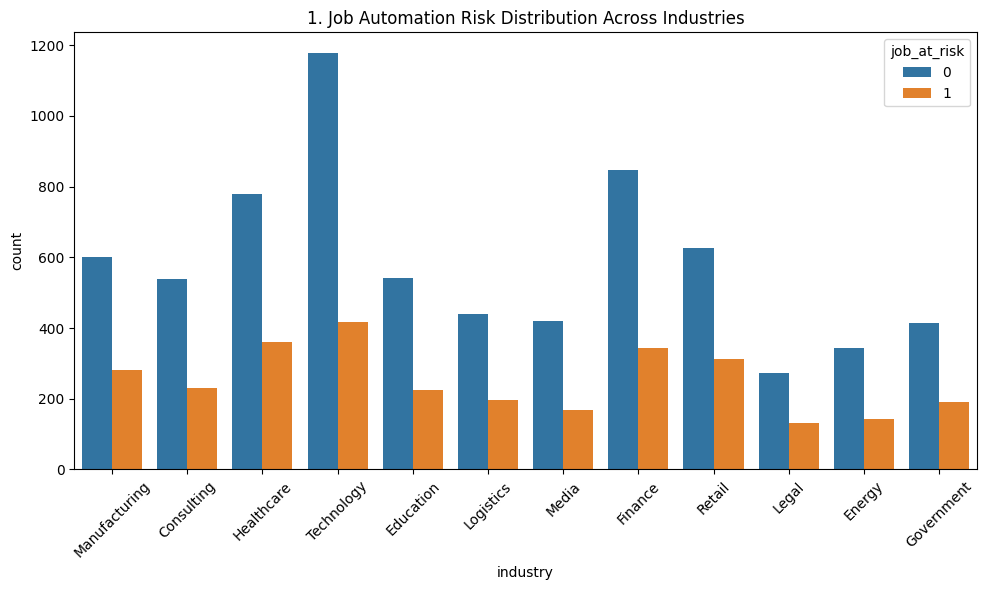

In [13]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='industry', hue='job_at_risk')
plt.title(f'{plot_no}. Job Automation Risk Distribution Across Industries')
plt.xticks(rotation=45)
show_fig()
plot_no += 1

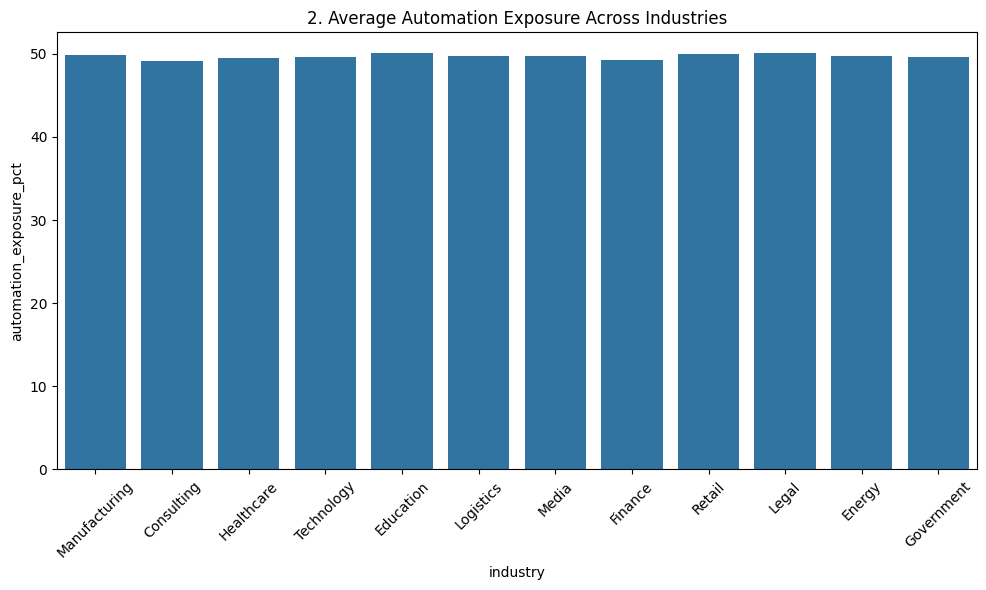

In [14]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='industry', y='automation_exposure_pct', errorbar=None)
plt.title(f'{plot_no}. Average Automation Exposure Across Industries')
plt.xticks(rotation=45)
show_fig()
plot_no += 1

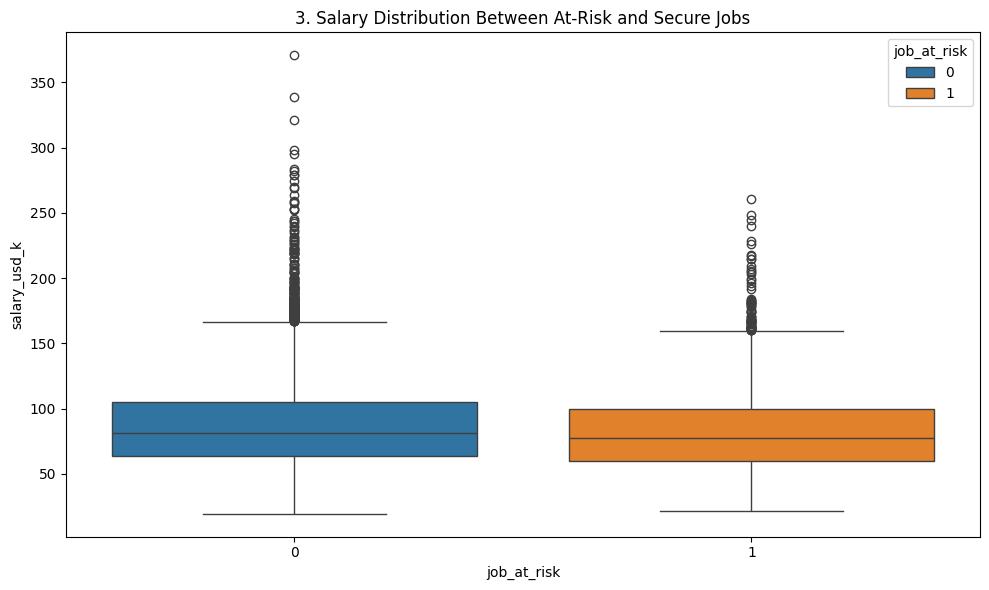

In [15]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='job_at_risk', y='salary_usd_k', hue='job_at_risk')
plt.title(f'{plot_no}. Salary Distribution Between At-Risk and Secure Jobs')
show_fig()
plot_no += 1

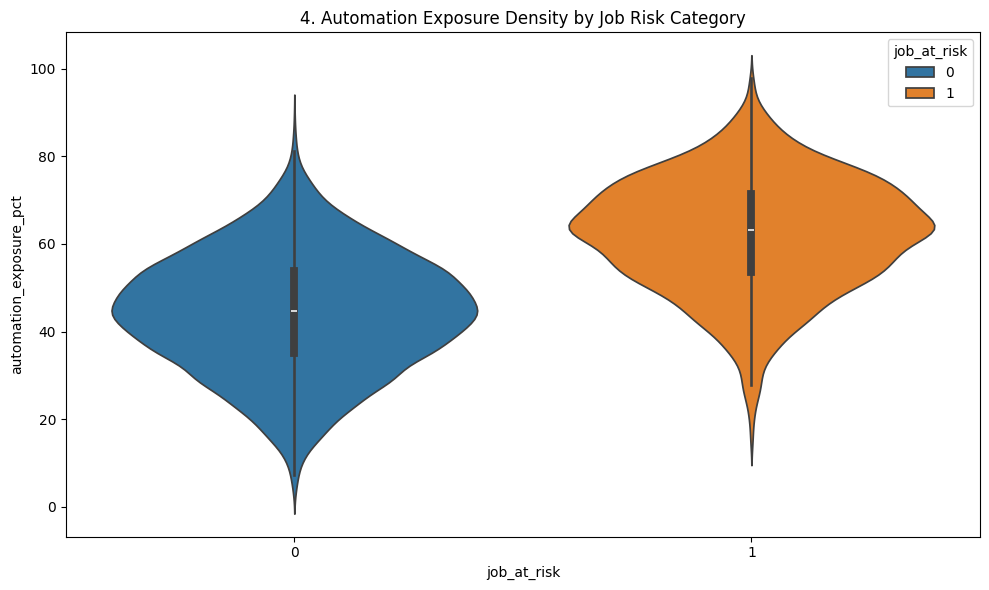

In [16]:
fig = plt.figure(figsize=(10,6))
sns.violinplot(data=df, x='job_at_risk', y='automation_exposure_pct', hue='job_at_risk')
plt.title(f'{plot_no}. Automation Exposure Density by Job Risk Category')
show_fig()
plot_no += 1

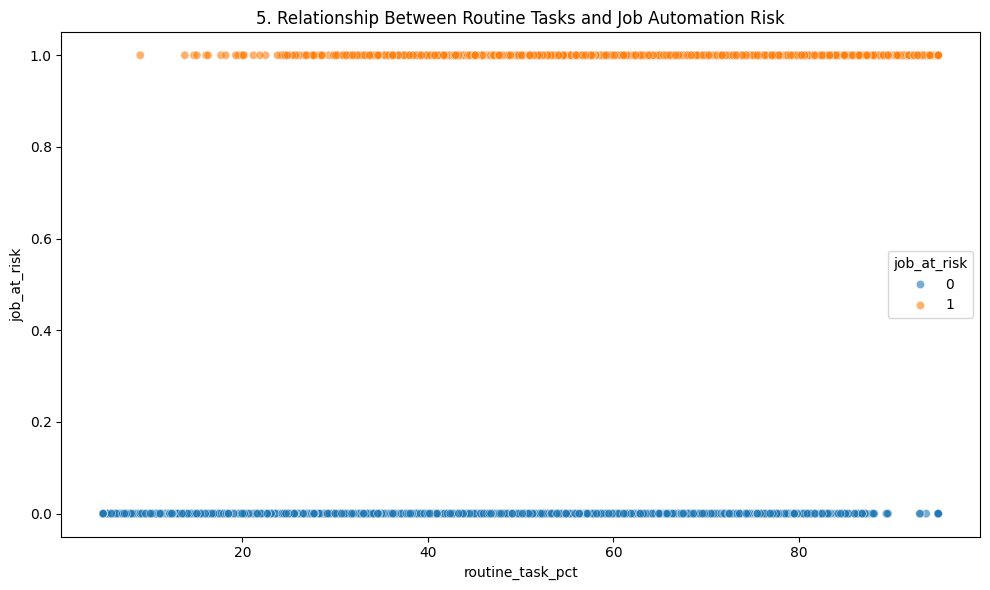

In [17]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='routine_task_pct', y='job_at_risk', hue='job_at_risk', alpha=0.6)
plt.title(f'{plot_no}. Relationship Between Routine Tasks and Job Automation Risk')
show_fig()
plot_no += 1

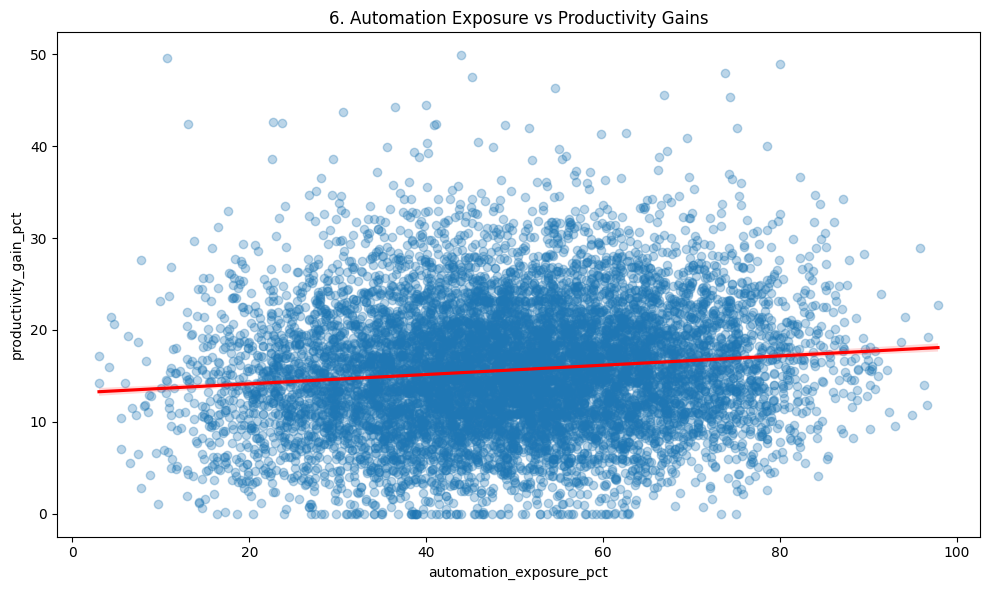

In [18]:
fig = plt.figure(figsize=(10,6))
sns.regplot(data=df, x='automation_exposure_pct', y='productivity_gain_pct', scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
plt.title(f'{plot_no}. Automation Exposure vs Productivity Gains')
show_fig()
plot_no += 1

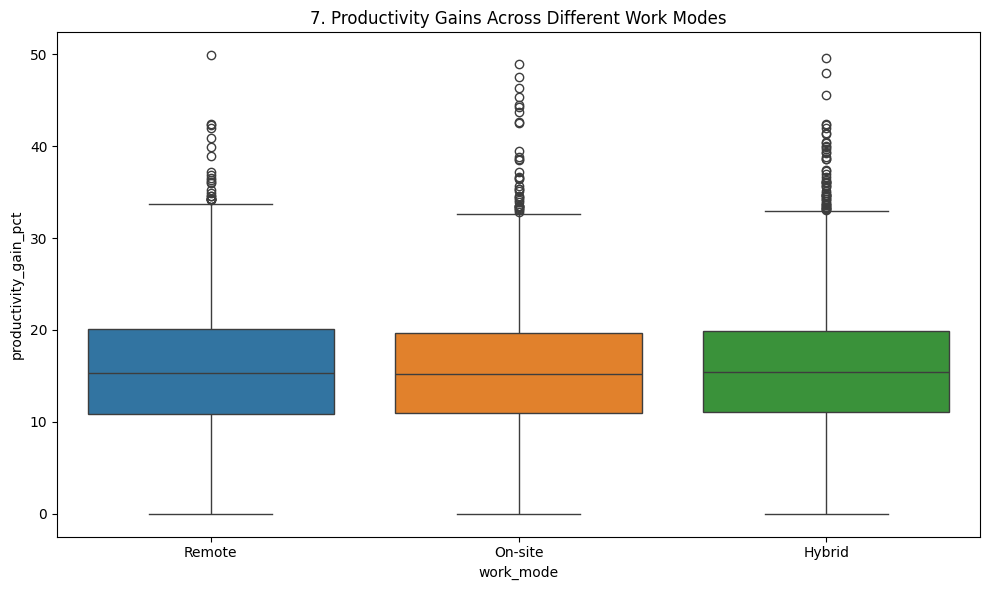

In [19]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='work_mode', y='productivity_gain_pct', hue='work_mode')
plt.title(f'{plot_no}. Productivity Gains Across Different Work Modes')
show_fig()
plot_no += 1

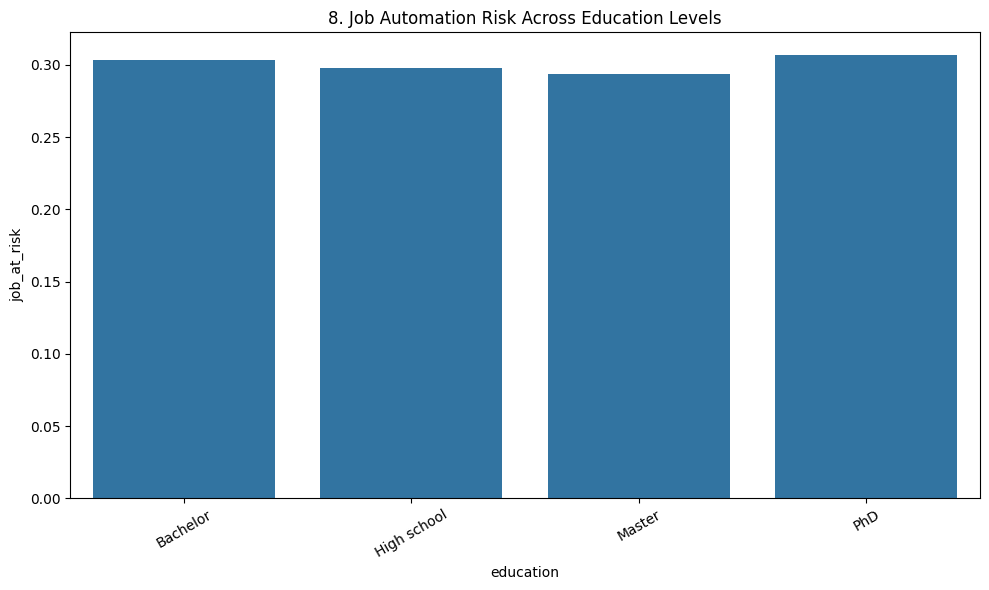

In [20]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='education', y='job_at_risk', errorbar=None)
plt.title(f'{plot_no}. Job Automation Risk Across Education Levels')
plt.xticks(rotation=30)
show_fig()
plot_no += 1

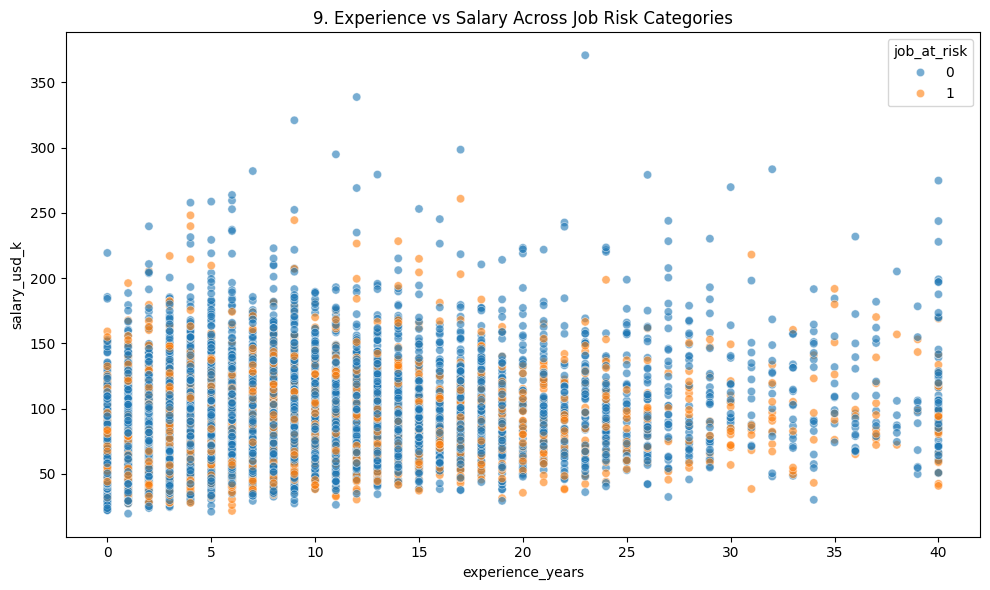

In [21]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='experience_years', y='salary_usd_k', hue='job_at_risk', alpha=0.6)
plt.title(f'{plot_no}. Experience vs Salary Across Job Risk Categories')
show_fig()
plot_no += 1

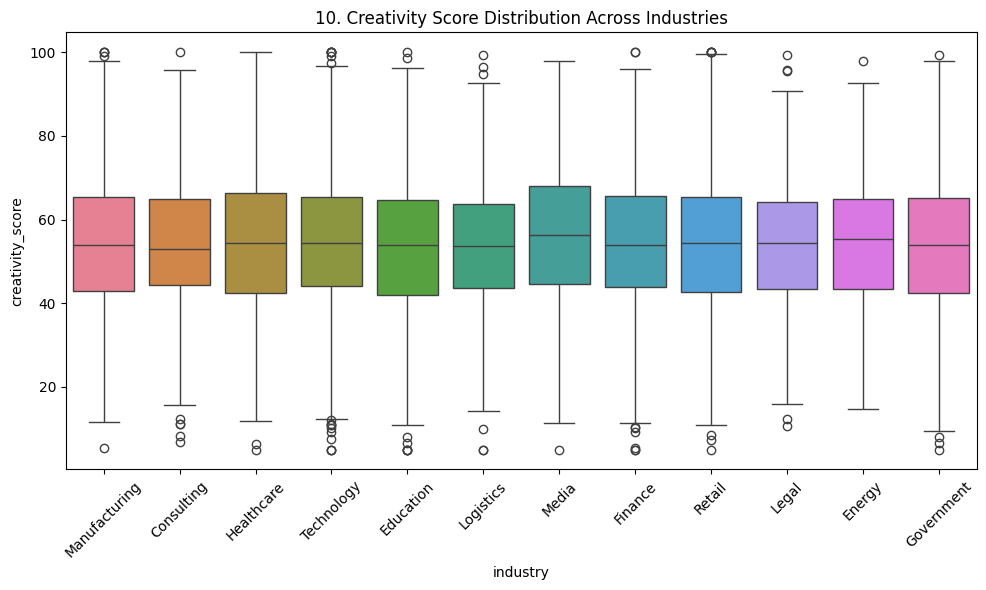

In [22]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='industry', y='creativity_score', hue='industry')
plt.title(f'{plot_no}. Creativity Score Distribution Across Industries')
plt.xticks(rotation=45)
show_fig()
plot_no += 1

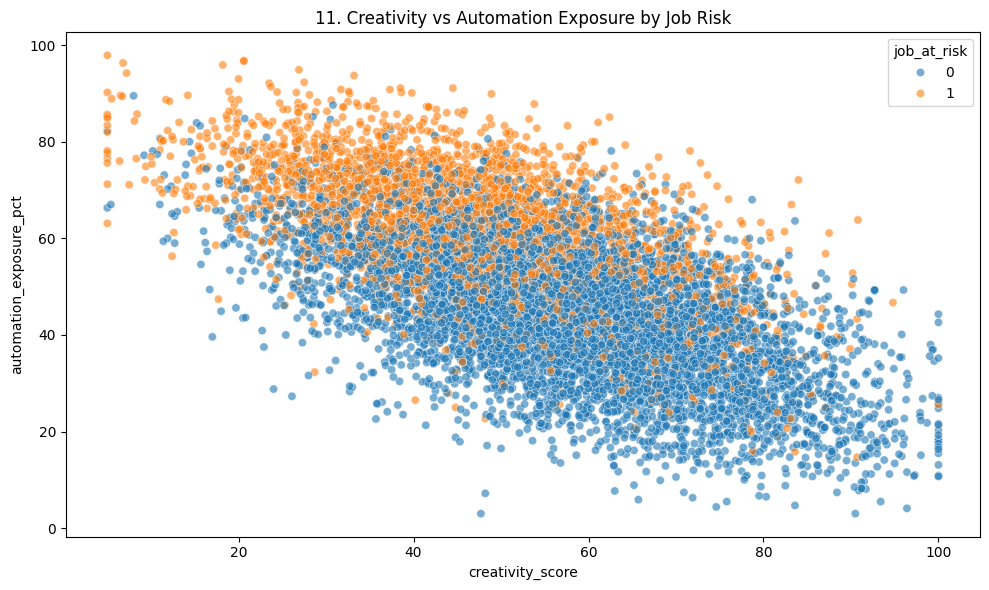

In [23]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='creativity_score', y='automation_exposure_pct', hue='job_at_risk', alpha=0.6)
plt.title(f'{plot_no}. Creativity vs Automation Exposure by Job Risk')
show_fig()
plot_no += 1

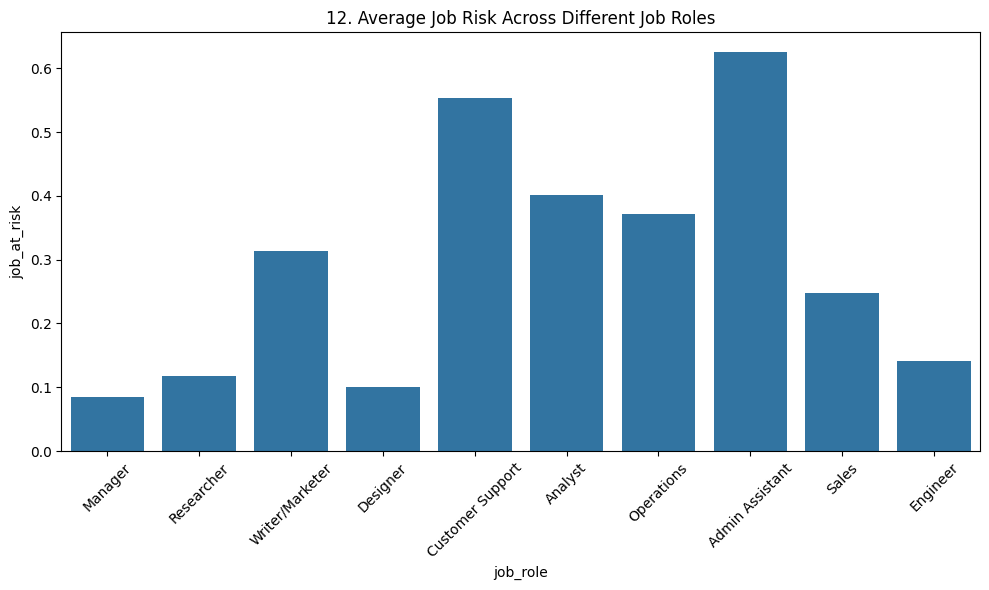

In [24]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='job_role', y='job_at_risk', errorbar=None)
plt.title(f'{plot_no}. Average Job Risk Across Different Job Roles')
plt.xticks(rotation=45)
show_fig()
plot_no += 1

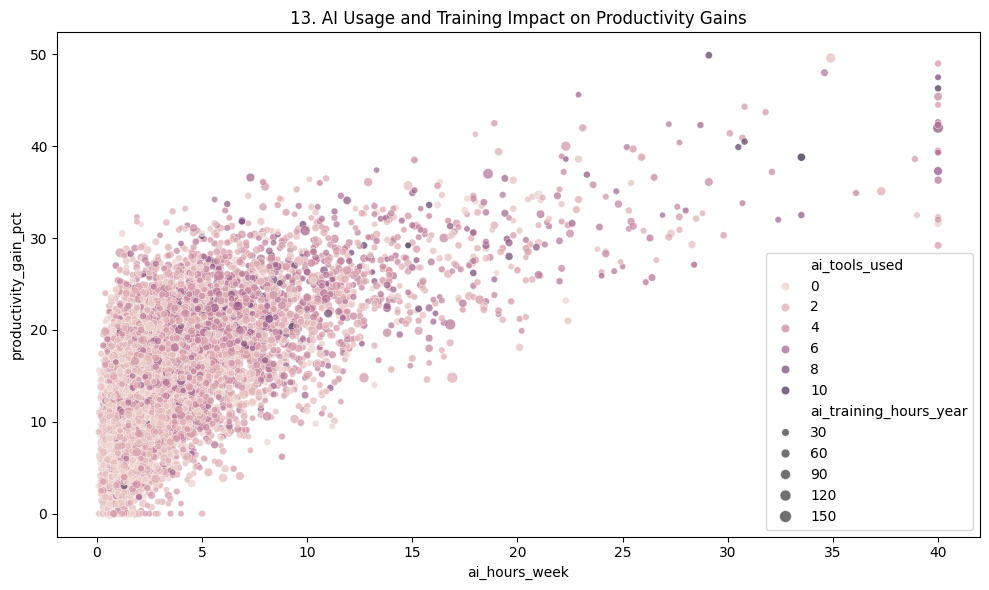

In [25]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='ai_hours_week', y='productivity_gain_pct', hue='ai_tools_used', size='ai_training_hours_year', alpha=0.7)
plt.title(f'{plot_no}. AI Usage and Training Impact on Productivity Gains')
show_fig()
plot_no += 1

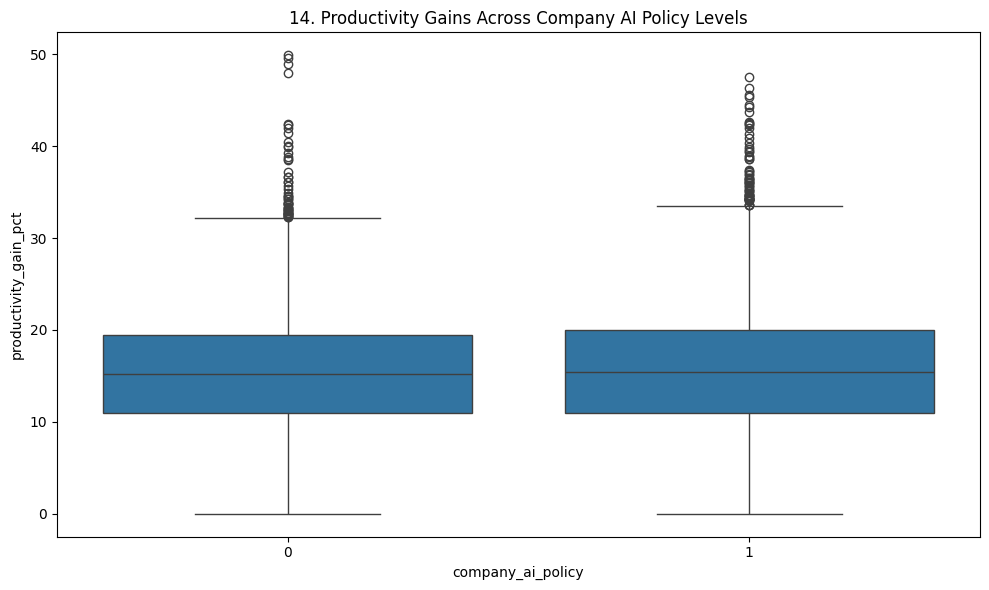

In [26]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='company_ai_policy', y='productivity_gain_pct')
plt.title(f'{plot_no}. Productivity Gains Across Company AI Policy Levels')
show_fig()
plot_no += 1

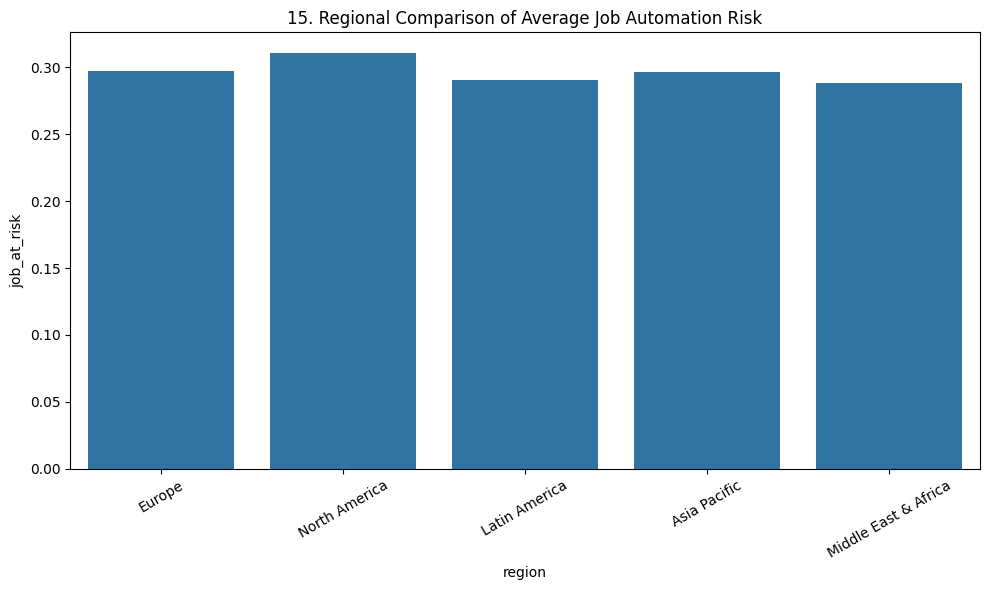

In [27]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='region', y='job_at_risk', errorbar=None)
plt.title(f'{plot_no}. Regional Comparison of Average Job Automation Risk')
plt.xticks(rotation=30)
show_fig()
plot_no += 1

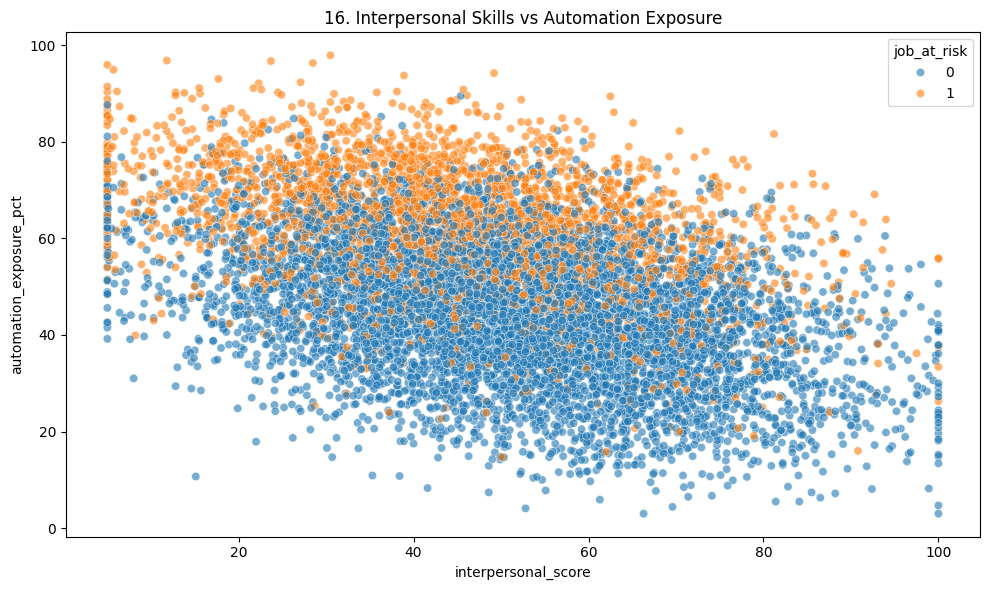

In [28]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='interpersonal_score', y='automation_exposure_pct', hue='job_at_risk', alpha=0.6)
plt.title(f'{plot_no}. Interpersonal Skills vs Automation Exposure')
show_fig()
plot_no += 1

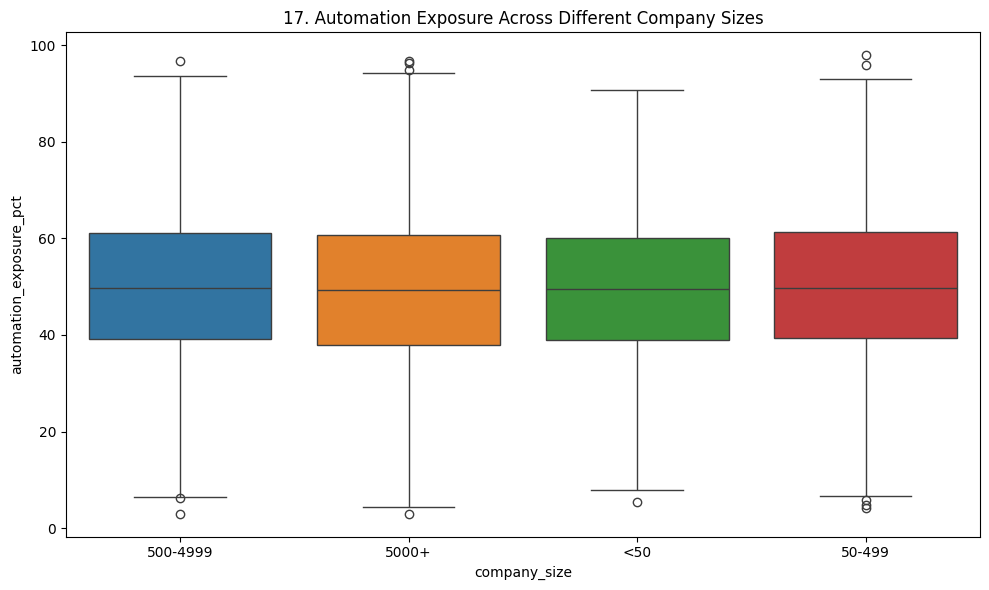

In [29]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='company_size', y='automation_exposure_pct', hue='company_size')
plt.title(f'{plot_no}. Automation Exposure Across Different Company Sizes')
show_fig()
plot_no += 1

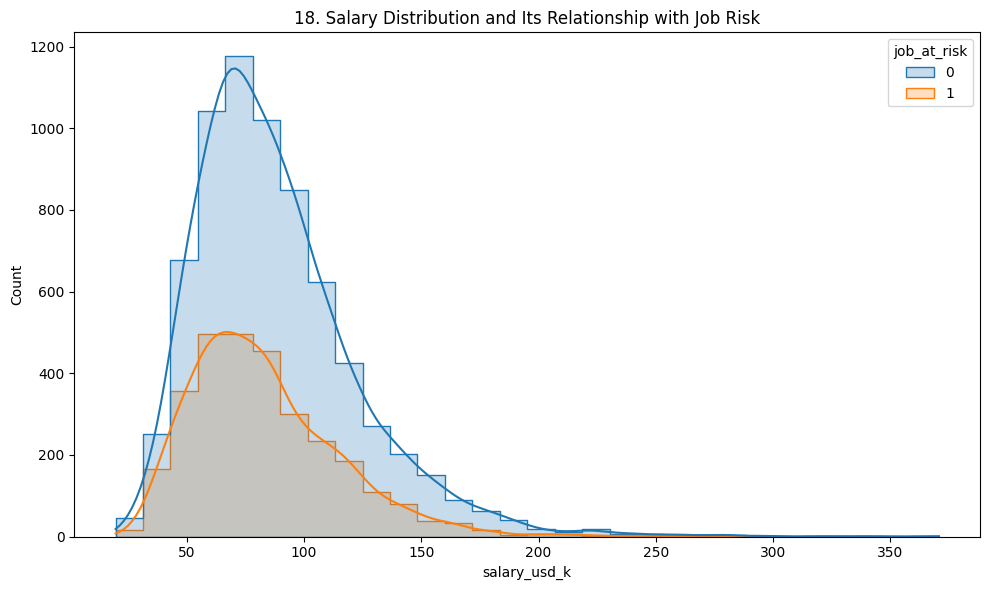

In [30]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='salary_usd_k', hue='job_at_risk', kde=True, bins=30, element='step')
plt.title(f'{plot_no}. Salary Distribution and Its Relationship with Job Risk')
show_fig()
plot_no += 1

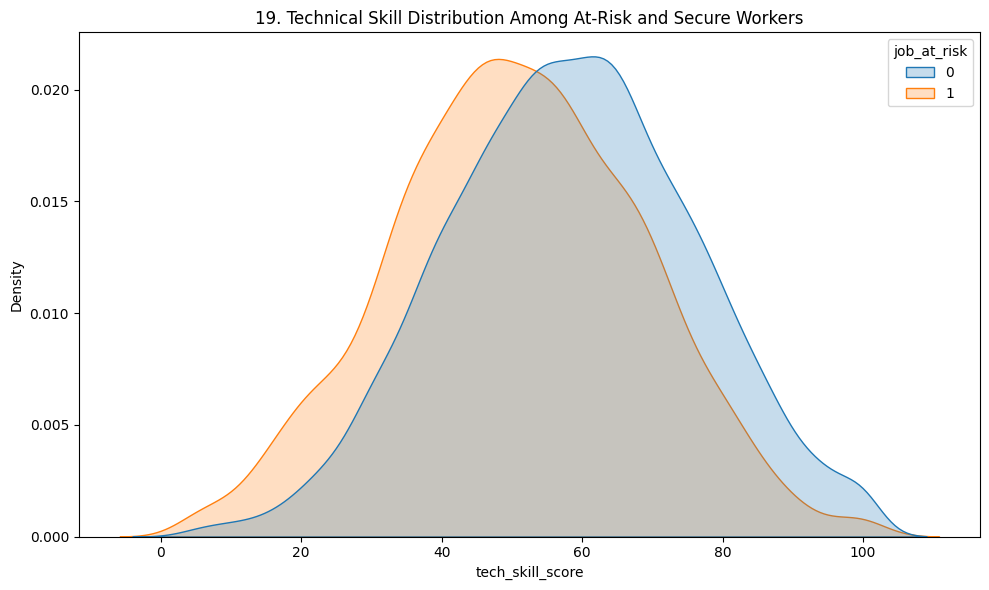

In [31]:
fig = plt.figure(figsize=(10,6))
sns.kdeplot(data=df, x='tech_skill_score', hue='job_at_risk', fill=True, common_norm=False)
plt.title(f'{plot_no}. Technical Skill Distribution Among At-Risk and Secure Workers')
show_fig()
plot_no += 1

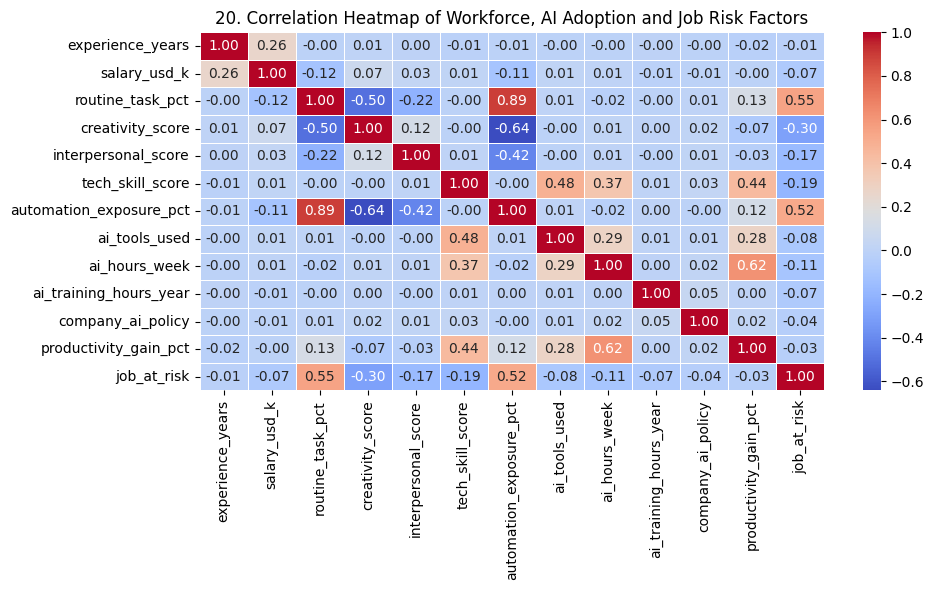

In [32]:
fig = plt.figure(figsize=(10,6))
corr = df.select_dtypes(include='number').drop(columns=['worker_id'], errors='ignore').corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title(f'{plot_no}. Correlation Heatmap of Workforce, AI Adoption and Job Risk Factors')
show_fig()
plot_no += 1

# Model Training

## Remove unnecessary ID column

In [33]:
data = df.drop(columns=['worker_id'], errors='ignore').copy()

## Separate features and target

In [34]:
X = data.drop(columns=['job_at_risk'])
y = data['job_at_risk']

## Identify numerical and categorical columns

In [35]:
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

## Create numerical preprocessing

In [36]:
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

## Create categorical preprocessing

In [37]:
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

## Combine preprocessing

In [38]:
preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

## Create complete model pipeline

In [39]:
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', HistGradientBoostingClassifier(random_state=42))
])

## Split training and testing data

In [40]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

## Define hyperparameter search

In [41]:
param_grid = {
    'model__learning_rate': [0.03, 0.05, 0.08, 0.1],
    'model__max_iter': [100, 200, 300],
    'model__max_leaf_nodes': [15, 25, 31],
    'model__l2_regularization': [0, 0.1, 1, 5],
    'model__min_samples_leaf': [10, 20, 30]
}

## Perform hyperparameter tuning

In [42]:
search = RandomizedSearchCV(
    pipeline,
    param_grid,
    n_iter=20,
    cv=3,
    scoring='accuracy',
    n_jobs=-1,
    random_state=42,
    verbose=1
)

## Train the best model

In [43]:
search.fit(X_train, y_train)
best_model = search.best_estimator_

Fitting 3 folds for each of 20 candidates, totalling 60 fits


## Generate predictions

In [44]:
y_pred = best_model.predict(X_test)

## Calculate model accuracy

In [45]:
accuracy = accuracy_score(y_test, y_pred)
print("Best Parameters:", search.best_params_)
print(f"\nModel Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

Best Parameters: {'model__min_samples_leaf': 20, 'model__max_leaf_nodes': 15, 'model__max_iter': 200, 'model__learning_rate': 0.03, 'model__l2_regularization': 5}

Model Accuracy: 81.90%

Classification Report:

              precision    recall  f1-score   support

           0       0.84      0.91      0.88      1400
           1       0.74      0.60      0.67       600

    accuracy                           0.82      2000
   macro avg       0.79      0.76      0.77      2000
weighted avg       0.81      0.82      0.81      2000



## Plot confusion matrix

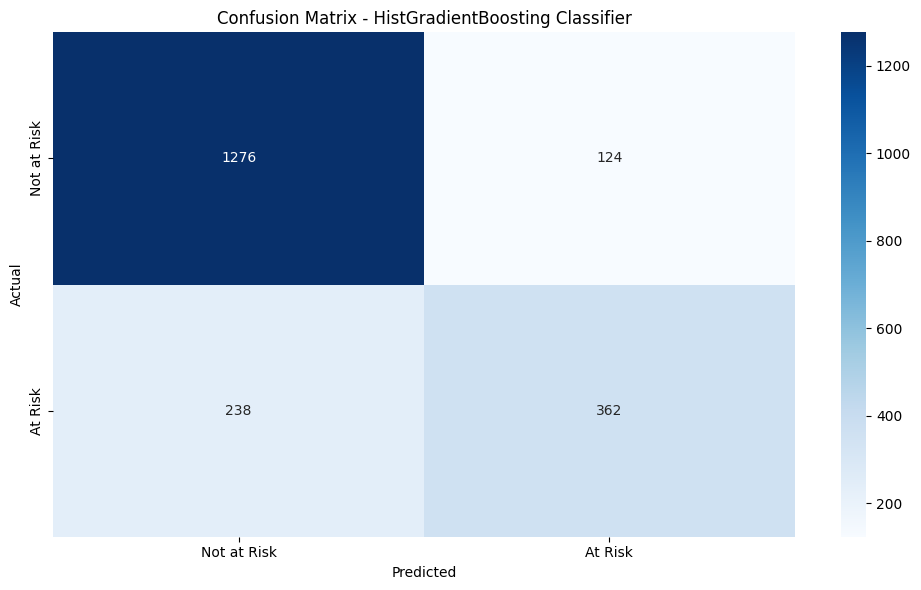

In [46]:
fig = plt.figure(figsize=(10,6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not at Risk', 'At Risk'],
            yticklabels=['Not at Risk', 'At Risk'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - HistGradientBoosting Classifier')
show_fig()